Week 3 – Model Improvement & Optimization

In [24]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split  
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import matplotlib.pyplot as plt

In [25]:
df = pd.read_csv("../data/electricity_cleaned.csv")
df.head()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Datetime,Month
0,0.256,0.106,242.00,1.2,0.0,0.0,1.0,2010-07-07 18:10:00,7
1,0.466,0.352,237.22,2.4,0.0,2.0,0.0,2007-05-14 06:50:00,5
2,0.758,0.194,238.66,3.2,0.0,1.0,0.0,2007-09-26 18:10:00,9
3,1.290,0.046,240.64,5.4,1.0,0.0,18.0,2007-06-19 07:30:00,6
4,0.428,0.202,242.23,1.8,0.0,2.0,1.0,2010-05-10 04:43:00,5


In [26]:
if "Datetime" in df.columns:
    df.drop("Datetime", axis=1, inplace=True)

In [27]:
X = df.drop("Global_active_power", axis=1)
y = df["Global_active_power"]

In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X,y,test_size=0.2,random_state=42
)

In [29]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [30]:
best_model = RandomForestRegressor(
    n_estimators=150,
    random_state=42
)

best_model.fit(X_train, y_train)

,n_estimators,150
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [31]:
best_prediction = best_model.predict(X_test)

In [32]:
print("Improved Random Forest Results")

print("MAE :", mean_absolute_error(y_test, best_prediction))
print("MSE :", mean_squared_error(y_test, best_prediction))
print("RMSE :", np.sqrt(mean_squared_error(y_test, best_prediction)))
print("R2 Score :", r2_score(y_test, best_prediction))

Improved Random Forest Results
MAE : 0.019359505113381907
MSE : 0.0012187796057285892
RMSE : 0.0349110241288993
R2 Score : 0.9989252062053922


In [33]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": best_model.feature_importances_
})
importance

,Feature,Importance
0,Global_reactive_power,0.000583
1,Voltage,0.000653
2,Global_intensity,0.998151
3,Sub_metering_1,0.000216
4,Sub_metering_2,0.000105
5,Sub_metering_3,0.000146
6,Month,0.000147


In [34]:
importance = importance.sort_values(
    by="Importance",
    ascending=False
)
importance

,Feature,Importance
2,Global_intensity,0.998151
1,Voltage,0.000653
0,Global_reactive_power,0.000583
3,Sub_metering_1,0.000216
6,Month,0.000147
5,Sub_metering_3,0.000146
4,Sub_metering_2,0.000105


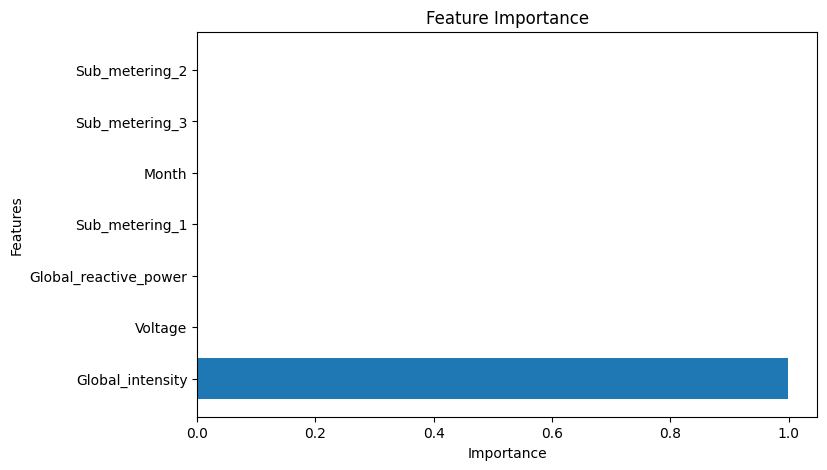

In [35]:
plt.figure(figsize=(8,5))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.title("Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.show()

In [36]:
sample = X_test[:1]

prediction = best_model.predict(sample)

print("Predicted Electricity Consumption:")
print(prediction)

Predicted Electricity Consumption:
[0.13973937]


In [37]:
comparison = pd.DataFrame({
    "Actual": y_test.iloc[:10].values,
    "Predicted": best_prediction[:10]
})
comparison

,Actual,Predicted
0,0.140,0.139739
1,0.584,0.571627
2,0.182,0.213920
3,0.308,0.262067
4,1.526,1.510253
5,0.592,0.604707
6,0.238,0.230813
7,3.850,3.851747
8,0.316,0.329013
9,0.336,0.322600


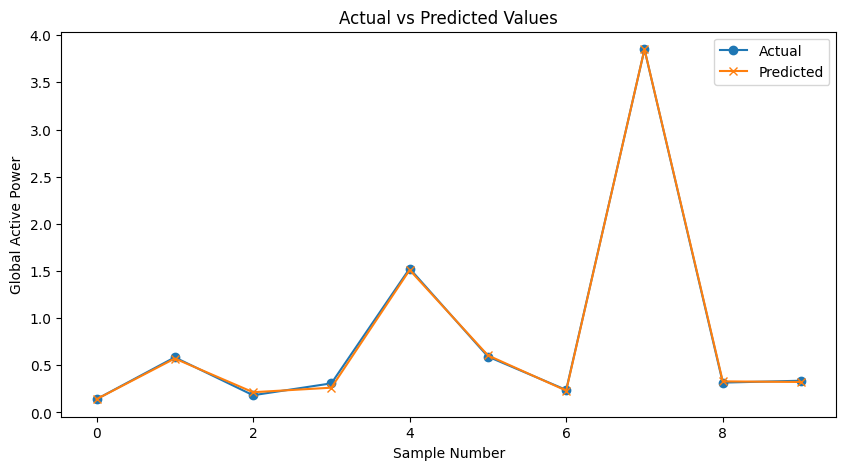

In [38]:
plt.figure(figsize=(10,5))

plt.plot(comparison["Actual"], marker="o", label="Actual")
plt.plot(comparison["Predicted"], marker="x", label="Predicted")

plt.title("Actual vs Predicted Values")
plt.xlabel("Sample Number")
plt.ylabel("Global Active Power")
plt.legend()
plt.show()

In [39]:
import joblib

joblib.dump(best_model, "model.pkl")
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']